# COMPASS — manuscript figures

**Are the higher-order parameter interactions reported in phenotype-conditioned
neuronal model ensembles neuron-specific biological signatures, or generic
consequences of nonlinear model structure, parameter sampling, covariance and
conditioning on shared outputs?**

This notebook builds the six main-text figures of the manuscript. It contains
**no analysis logic**: every value is read from the frozen tables in
`results/analyses/`, `results/manifests/` and `results/traces/` that
`tools/run_analysis.py` produced. `docs/RESULTS.md` is the narrative record of
the same tables; `docs/figure_legends.md` holds the legends that accompany
these figures.

| figure | content | claim level |
|---|---|---|
| 1 | The model panel and the conditioning design | — |
| 2 | The instrument: estimator validation and two non-neuronal comparators | Observed / Statistical |
| 3 | **Result 1** — conditioning an independent prior manufactures dependence | Statistical |
| 4 | **Result 2** — the naive synergy statistic is not a statistic | Statistical |
| 5 | **Results 3–5** — the regime, not the neuron, sets the sign; RSI behaves oppositely | Statistical |
| 6 | **Result 6** — do statistically synergistic tuples interact functionally? | Functional |

Output: `results/figures/Figure_N.pdf` (vector) and `Figure_N.png` (600 dpi),
180 mm wide, sized for a double-column manuscript.

To run: `jupyter nbconvert --execute --to notebook --inplace notebooks/COMPASS_figures.ipynb`
(or set `COMPASS_ROOT` and run from anywhere).

In [1]:
"""Setup: paths, house style, palette, loaders."""
%matplotlib inline
import json, os, warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib as mpl
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D
from matplotlib.patches import Patch, FancyArrowPatch, FancyBboxPatch
from matplotlib.ticker import FixedLocator, FixedFormatter, NullLocator

warnings.filterwarnings("ignore")

_env = os.environ.get("COMPASS_ROOT", "").strip()
ROOT = Path(_env).resolve() if _env else (
    Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd())
assert (ROOT / "results" / "analyses").is_dir(), (
    f"{ROOT} does not look like the COMPASS repository root; "
    "set COMPASS_ROOT or run this notebook from notebooks/")

AN = ROOT / "results" / "analyses"
MAN = ROOT / "results" / "manifests"
TR = ROOT / "results" / "traces"
FIGDIR = ROOT / "results" / "figures"
FIGDIR.mkdir(parents=True, exist_ok=True)
EXP = "screening"
print("repository root:", ROOT)

# ---------------------------------------------------------------- geometry --
MM = 1 / 25.4
W2 = 180 * MM          # double-column width
W1 = 88 * MM           # single-column width
DPI = 600

# ---------------------------------------------------------------- palette ---
# Polarity is the load-bearing colour axis and is diverging: blue = synergy
# (Omega < 0), red = redundancy (Omega > 0), neutral grey at zero.  Under
# simulated deuteranopia and protanopia the two poles are separated by
# dE > 85 and the eight categorical model colours by dE > 12; every
# categorical series also carries its own marker, so colour is never the only
# channel.  Hue family encodes source lineage: the two Hodgkin-Huxley models
# share blues, the two Pospischil models share oranges.
SYNERGY, REDUNDANCY, NEUTRAL = "#2a78d6", "#e34948", "#9d9c98"
INK, INK2, INK3, GRID = "#111111", "#4d4c49", "#8a8985", "#dedcd8"
FAINT, BAND = "#c9c7c2", "#f2c9c6"
DIVERGING = mpl.colors.LinearSegmentedColormap.from_list(
    "compass_div", [SYNERGY, "#f4f3f0", REDUNDANCY])

MODEL_ORDER = ["hh_point", "hh_cable", "pospischil_rs", "pospischil_fs",
               "khaliq_purkinje", "mainen_l5pc", "migliore_ca1", "bbp_l5pc"]
MODEL_LABEL = {"hh_point": "HH point", "hh_cable": "HH cable",
               "pospischil_rs": "Cortical RS", "pospischil_fs": "Cortical FS",
               "khaliq_purkinje": "Purkinje", "mainen_l5pc": "L5PC (Mainen)",
               "migliore_ca1": "CA1 (Migliore)", "bbp_l5pc": "L5PC (BBP)"}
MODEL_COLOR = dict(zip(MODEL_ORDER,
    ["#2a78d6", "#8ec4f2", "#eb6834", "#f6b28c",
     "#1baf7a", "#4a3aa7", "#eda100", "#8a1b52"]))
MODEL_MARKER = dict(zip(MODEL_ORDER, ["o", "s", "^", "v", "D", "P", "X", "*"]))
# fails the N3 convergence gate, so it is absent from every primary-cohort
# table; it is still shown where the underlying table retains it, marked.
GATE_EXCLUDED = {"mainen_l5pc"}
GATE_NOTE = ("$\\ddag$ fails the convergence gate (N3) and is excluded from primary "
             "inference; shown only where the source table retains it")

TOL_ORDER = ["permissive", "moderate", "strict", "very_strict"]
TOL_LABEL = {"permissive": "3.0 z", "moderate": "2.0 z",
             "strict": "1.0 z", "very_strict": "0.5 z"}
TOL_REGIME = {"permissive": "E3", "moderate": "E3b", "strict": "E4", "very_strict": "E4b"}
KIND_LABEL = {"top_synergy": "top synergy", "control_middle": "matched control",
              "control_random": "random control"}
KIND_COLOR = {"top_synergy": SYNERGY, "control_middle": "#8a8985", "control_random": FAINT}
FEATURE_LABEL = {"mean_firing_rate_Hz": "firing rate", "first_isi_ms": "first ISI",
                 "ap_amplitude_mV": "AP amplitude", "ap_halfwidth_ms": "AP half-width",
                 "spike_count": "spike count"}


def apply_style():
    mpl.rcParams.update({
        "figure.facecolor": "white", "axes.facecolor": "white",
        "savefig.facecolor": "white", "savefig.bbox": "tight",
        "savefig.pad_inches": 0.02,
        "font.family": "sans-serif",
        "font.sans-serif": ["Arial", "Helvetica", "Liberation Sans", "DejaVu Sans"],
        "font.size": 7, "axes.labelsize": 7, "axes.titlesize": 7,
        "xtick.labelsize": 6.5, "ytick.labelsize": 6.5, "legend.fontsize": 6.3,
        "axes.titleweight": "regular", "axes.labelcolor": INK, "text.color": INK,
        "axes.edgecolor": INK3, "axes.linewidth": 0.6,
        "xtick.color": INK2, "ytick.color": INK2,
        "xtick.major.width": 0.6, "ytick.major.width": 0.6,
        "xtick.major.size": 2.4, "ytick.major.size": 2.4,
        "axes.grid": False, "grid.color": GRID, "grid.linewidth": 0.5,
        "axes.axisbelow": True, "axes.spines.top": False, "axes.spines.right": False,
        "legend.frameon": False, "legend.handlelength": 1.3,
        "legend.handletextpad": 0.45, "legend.labelspacing": 0.28,
        "legend.borderpad": 0.1, "legend.borderaxespad": 0.2,
        "lines.linewidth": 1.1, "lines.markersize": 3.4,
        "figure.dpi": 150, "pdf.fonttype": 42, "ps.fonttype": 42,
    })


apply_style()


def panel(ax, letter, dx=-0.14, dy=1.03):
    ax.text(dx, dy, letter, transform=ax.transAxes, fontsize=9,
            fontweight="bold", va="bottom", ha="left", color=INK)


def ygrid(ax, axis="y"):
    ax.grid(True, axis=axis, color=GRID, lw=0.5)
    ax.set_axisbelow(True)


def fixed_log_ticks(ax, values, axis="x"):
    """Plain tick labels on a log axis, no minor decade clutter."""
    a = ax.xaxis if axis == "x" else ax.yaxis
    a.set_major_locator(FixedLocator(values))
    a.set_major_formatter(FixedFormatter([f"{v:g}" for v in values]))
    a.set_minor_locator(NullLocator())


def mlab(m, mark=True):
    s = MODEL_LABEL.get(m, m)
    return s + ("$^\\ddag$" if (mark and m in GATE_EXCLUDED) else "")


def model_legend(fig, models, ncol=8, y=-0.005, note=False):
    fig.legend(handles=[Line2D([], [], color=MODEL_COLOR[m], marker=MODEL_MARKER[m],
                               ms=3.4, lw=0.9, label=mlab(m)) for m in models],
               ncol=ncol, loc="lower center", bbox_to_anchor=(0.5, y),
               columnspacing=1.0, handletextpad=0.4)
    if note and any(m in GATE_EXCLUDED for m in models):
        fig.text(0.5, y - 0.035, GATE_NOTE, ha="center", va="top",
                 fontsize=5.7, color=INK2, transform=fig.transFigure)


def save(fig, n):
    for ext in ("pdf", "png"):
        fig.savefig(FIGDIR / f"Figure_{n}.{ext}", dpi=DPI)
    w, h = fig.get_size_inches()
    print(f"  wrote Figure_{n}.pdf / .png  ({w/MM:.0f} x {h/MM:.0f} mm)")


# ---------------------------------------------------------------- loaders ---
def tab(name):
    p = AN / name
    return pd.read_parquet(p) if p.exists() else None


def js(name):
    p = AN / name
    return json.loads(p.read_text()) if p.exists() else None


endpoints = tab(f"endpoints_annotated_{EXP}.parquet")
curves = tab(f"order_curves_{EXP}.parquet")
rsi_tab = tab(f"rsi_{EXP}.parquet")
cond_shift = tab("conditioning_shift.parquet")
cov_shift = tab("covariance_shift.parquet")
vpart = tab("variance_partition.parquet")
lomo = tab("lomo.parquet")
clf = tab("classification.parquet")
stability = tab("module_stability.parquet")
pert = tab("perturbations.parquet")
pert_inf = tab("perturbation_inference.parquet")
sobol_sum = tab("sobol_summary.parquet")

bench = js("benchmarks.json")
reliab = js("estimator_reliability.json")
robust = js("robustness.json")
decision = js("decision.json")
pert_sum = js("perturbations_summary.json")
pert_prec = js("perturbation_inference.json")
mixed = js("mixed_effects.json")

manifests = {}
for p in sorted(MAN.glob("canonical_*.json")):
    r = json.loads(p.read_text())
    if r["model_id"] in MODEL_ORDER:
        manifests[r["model_id"]] = r
PANEL = [m for m in MODEL_ORDER if m in manifests]

# Analysis slices used throughout.
#   ENDPOINT slice  - Gaussian estimator, absolute (non-rheobase-normalised)
#                     protocols, max-z acceptance metric: one row per
#                     model x regime, which is what the endpoint figures need.
#   GAUSSIAN slice  - Gaussian estimator only, pooled over protocol family,
#                     acceptance metric and tuple order.  This is the slice
#                     `key_numbers.json` and RESULTS.md 7 report, so Figure 4
#                     uses it unchanged.
def sl_endpoint(df, metric=("none", "max_z")):
    q = (df.estimator == "gaussian") & (df.protocol_family == "absolute")
    if "metric" in df.columns:
        q &= df.metric.isin(metric)
    return df[q]


def sl_gaussian(df):
    return df[df.estimator == "gaussian"]


def sl_rsi(df):
    """RSI rows on the same acceptance metric as the endpoint slice.

    `rsi_screening.parquet` carries no protocol_family column but does carry
    both protocol families and both acceptance metrics as separate rows, so a
    plain row mean double-counts models unevenly.  Restrict to the max-z
    metric (the unconditioned prior has no metric) and average within model
    before averaging across models.
    """
    g = df[df.estimator == "gaussian"]
    return g[g.label.str.contains("max_z") | (g.regime == "E1")]


def per_model_mean(df, value, by="regime", model="model_id"):
    """Average within model first, so an unbalanced row count cannot weight
    one model more than another."""
    return df.groupby([by, model])[value].mean().groupby(by).mean()


print("panel:", ", ".join(mlab(m) for m in PANEL))
print("lineages:", len({manifests[m]["manifest"]["source_lineage_id"] for m in PANEL}))
print("tables loaded:",
      sum(x is not None for x in [endpoints, curves, rsi_tab, cond_shift, cov_shift,
                                  vpart, lomo, clf, stability, pert, pert_inf, sobol_sum]),
      "parquet,",
      sum(x is not None for x in [bench, reliab, robust, decision, pert_sum,
                                  pert_prec, mixed]), "json")

repository root: /home/claude/work/compass
panel: HH point, HH cable, Cortical RS, Cortical FS, Purkinje, L5PC (Mainen)$^\ddag$, CA1 (Migliore), L5PC (BBP)
lineages: 6
tables loaded: 12 parquet, 7 json


---
## Figure 1 — The model panel and the conditioning design

Eight independently constructed conductance-based models, spanning a
one-compartment Hodgkin–Huxley cell to a 2,304-compartment layer-5 pyramidal
reconstruction, six source lineages and forty-seven years of model development,
are driven through one sampling, conditioning and analysis pipeline. Panel
**D** is the experimental design: every ensemble descends from the *same*
independent prior, and the only manipulation that defines E3–E4b is how tightly
the accepted samples must reproduce each model's own canonical phenotype.

  wrote Figure_1.pdf / .png  (180 x 95 mm)


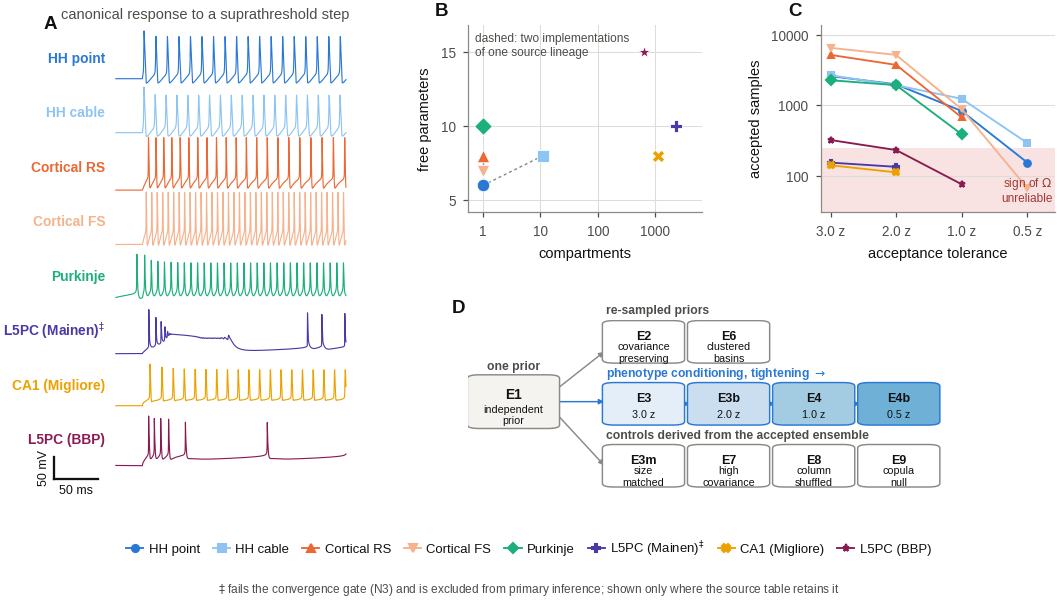

In [2]:
fig = plt.figure(figsize=(W2, 3.75))
gs = fig.add_gridspec(2, 3, width_ratios=[1.30, 1.0, 1.0], height_ratios=[1.0, 0.92],
                      wspace=0.46, hspace=0.60, left=0.045, right=0.995,
                      top=0.92, bottom=0.09)

# ---- A: canonical voltage responses, stacked -------------------------------
axA = fig.add_subplot(gs[:, 0])
OFFSET, T0, T1 = 120.0, 90.0, 350.0
LMARGIN = 80.0
for i, m in enumerate(PANEL):
    y0 = -i * OFFSET
    npz = TR / f"canonical_{m}.npz"
    if npz.exists():
        d = np.load(npz)
        t, v = d["step_hi_t"], d["step_hi_v"]
        sel = (t >= T0) & (t <= T1)
        axA.plot(t[sel] - T0, v[sel] + y0 + 65.0, color=MODEL_COLOR[m], lw=0.55,
                 solid_joinstyle="round")
    axA.text(-12, y0 + 45, mlab(m), fontsize=6.6, color=MODEL_COLOR[m],
             ha="right", va="center", fontweight="bold")
xb, yb = -70, -7 * OFFSET - 42
axA.plot([xb, xb + 50], [yb, yb], color=INK, lw=1.1, clip_on=False)
axA.plot([xb, xb], [yb, yb + 50], color=INK, lw=1.1, clip_on=False)
axA.text(xb + 25, yb - 12, "50 ms", fontsize=6, ha="center", va="top", color=INK)
axA.text(xb - 4, yb + 25, "50 mV", fontsize=6, ha="right", va="center",
         rotation=90, color=INK)
axA.set_xlim(-LMARGIN, 264)
axA.set_ylim(-7 * OFFSET - 70, 118)
axA.axis("off")
axA.set_title("canonical response to a suprathreshold step", fontsize=7,
              color=INK2, pad=3, loc="right")
panel(axA, "A", dx=-0.005, dy=0.985)

# ---- B: panel scope --------------------------------------------------------
axB = fig.add_subplot(gs[0, 1])
LINEAGE_PAIRS = [("hh_point", "hh_cable"), ("pospischil_rs", "pospischil_fs")]
for a, b in LINEAGE_PAIRS:
    axB.plot([manifests[a]["n_compartments"], manifests[b]["n_compartments"]],
             [manifests[a]["n_parameters"], manifests[b]["n_parameters"]],
             color=INK3, lw=0.7, ls=(0, (2, 2)), zorder=1)
for m in PANEL:
    r = manifests[m]
    axB.scatter(max(r["n_compartments"], 1), r["n_parameters"], s=36,
                color=MODEL_COLOR[m], marker=MODEL_MARKER[m],
                edgecolor="white", linewidth=0.4, zorder=3)
axB.set_xscale("log")
fixed_log_ticks(axB, [1, 10, 100, 1000], "x")
axB.set_xlim(0.55, 6500)
axB.set_ylim(4.2, 16.8)
axB.set_yticks([5, 10, 15])
axB.set_xlabel("compartments")
axB.set_ylabel("free parameters")
ygrid(axB, "both")
axB.text(0.03, 0.96, "dashed: two implementations\nof one source lineage",
         transform=axB.transAxes, fontsize=5.7, va="top", color=INK2, linespacing=1.2)
panel(axB, "B")

# ---- C: usable sample size collapses with tolerance ------------------------
axC = fig.add_subplot(gs[0, 2])
ep = sl_endpoint(endpoints)
for m in PANEL:
    ns = []
    for t in TOL_ORDER:
        g = ep[(ep.model_id == m) & (ep.regime == TOL_REGIME[t])]
        ns.append(float(g["n_samples"].iloc[0]) if len(g) else np.nan)
    axC.plot(range(4), ns, color=MODEL_COLOR[m], marker=MODEL_MARKER[m],
             ms=3.2, lw=0.9, clip_on=False)
axC.axhspan(25, 250, color=BAND, alpha=0.5, zorder=0, lw=0)
axC.text(3.38, 62, "sign of $\\Omega$\nunreliable", fontsize=5.7, color="#a33a34",
         ha="right", va="center", linespacing=1.15)
axC.set_yscale("log")
fixed_log_ticks(axC, [100, 1000, 10000], "y")
axC.set_xticks(range(4)); axC.set_xticklabels([TOL_LABEL[t] for t in TOL_ORDER])
axC.set_xlabel("acceptance tolerance")
axC.set_ylabel("accepted samples")
axC.set_ylim(30, 14000)
axC.set_xlim(-0.15, 3.42)
ygrid(axC)
panel(axC, "C")

# ---- D: the ensemble design ------------------------------------------------
axD = fig.add_subplot(gs[1, 1:])
axD.set_xlim(0, 1); axD.set_ylim(0, 1); axD.axis("off")


def box(x, y, w, h, code, sub, fc, ec, tc=INK, fs=6.0):
    axD.add_patch(FancyBboxPatch((x, y), w, h, boxstyle="round,pad=0.006,rounding_size=0.02",
                                 facecolor=fc, edgecolor=ec, linewidth=0.7, zorder=2))
    axD.text(x + w / 2, y + h * 0.63, code, ha="center", va="center", fontsize=fs,
             fontweight="bold", color=tc, zorder=3)
    axD.text(x + w / 2, y + h * 0.24, sub, ha="center", va="center", fontsize=5.2,
             color=tc, zorder=3)


def arrow(x0, y0, x1, y1, color=INK3, lw=0.7, style="-|>"):
    axD.add_patch(FancyArrowPatch((x0, y0), (x1, y1), arrowstyle=style,
                                  mutation_scale=5, color=color, lw=lw,
                                  shrinkA=0, shrinkB=0, zorder=1))


W, H = 0.128, 0.235
box(0.005, 0.375, 0.145, 0.30, "E1", "independent\nprior", "#f4f3f0", INK3, fs=6.6)
axD.text(0.0775, 0.71, "one prior", ha="center", fontsize=5.8, color=INK2,
         fontweight="bold")

# prior variants
for k, (c, s) in enumerate([("E2", "covariance\npreserving"), ("E6", "clustered\nbasins")]):
    box(0.235 + k * 0.145, 0.755, W, H, c, s, "white", INK3)
arrow(0.152, 0.60, 0.232, 0.815)
axD.text(0.235, 1.035, "re-sampled priors", fontsize=5.8, color=INK2, fontweight="bold")

# conditioning chain
CH = [("E3", "3.0 z"), ("E3b", "2.0 z"), ("E4", "1.0 z"), ("E4b", "0.5 z")]
for k, (c, s) in enumerate(CH):
    x = 0.235 + k * 0.145
    shade = mpl.colors.to_hex(plt.get_cmap("Blues")(0.10 + 0.13 * k))
    box(x, 0.395, W, H, c, s, shade, SYNERGY, fs=6.0)
    if k:
        arrow(x - 0.017, 0.5125, x - 0.002, 0.5125, color=SYNERGY)
arrow(0.152, 0.525, 0.232, 0.525, color=SYNERGY)
axD.text(0.235, 0.672, "phenotype conditioning, tightening $\\rightarrow$",
         fontsize=5.8, color=SYNERGY, fontweight="bold")

# controls derived from E3
for k, (c, s) in enumerate([("E3m", "size\nmatched"), ("E7", "high\ncovariance"),
                            ("E8", "column\nshuffled"), ("E9", "copula\nnull")]):
    box(0.235 + k * 0.145, 0.035, W, H, c, s, "white", INK3)
arrow(0.152, 0.45, 0.232, 0.155)
axD.text(0.235, 0.312, "controls derived from the accepted ensemble",
         fontsize=5.8, color=INK2, fontweight="bold")
panel(axD, "D", dx=-0.028, dy=1.02)

model_legend(fig, PANEL, ncol=8, y=-0.035, note=True)
save(fig, 1)
plt.show()

---
## Figure 2 — The instrument, and two systems with no neurons in them

No neuronal number is believed until the estimators recover known structure with
the right sign. Panel **A** is the bound on every Gaussian O-information result
in this study and in the literature it addresses: the covariance-based estimator
and its rank-transformed copula variant return *exactly zero* for synergy
carried by a product, where a $k$-NN estimator returns $-0.84$ and $-1.57$ nats.
Panels **C**–**D** run the identical conditioning workflow on a gene circuit and
an ecological community: the phenomenon appears in full in a six-parameter
system with no neurons in it — and fails to appear when the phenotype barely
constrains the parameters, which is what makes it a mechanism rather than an
artefact of running the machinery.

  wrote Figure_2.pdf / .png  (180 x 86 mm)


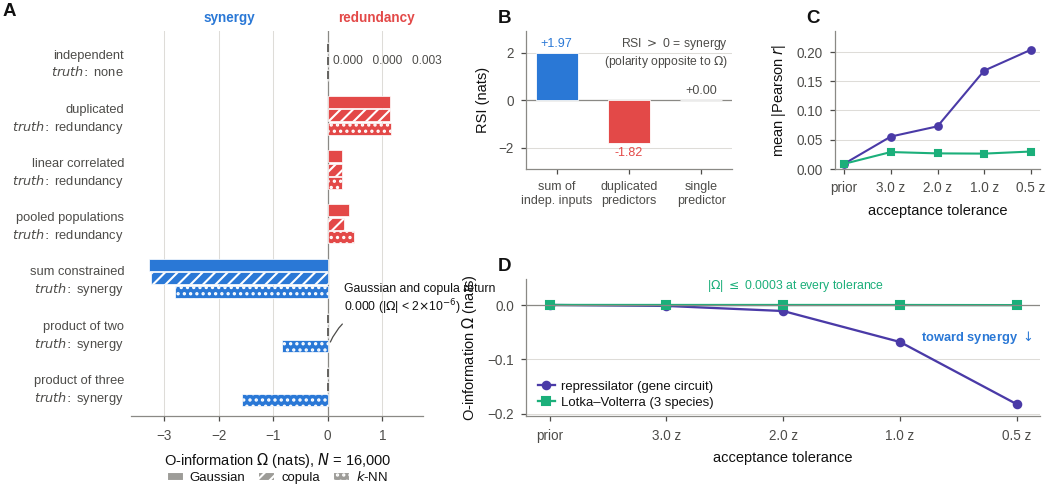

In [3]:
bv = pd.DataFrame(bench["estimator_validation"])
NBEN = int(bv.n.max())
bv = bv[bv.n == NBEN]
SYS_ORDER = ["independent", "duplicated", "linear_correlated", "mixture_pooled",
             "sum_constrained", "xor_like", "multiplicative"]
SYS_LABEL = {"independent": "independent", "duplicated": "duplicated",
             "linear_correlated": "linear correlated", "mixture_pooled": "pooled populations",
             "sum_constrained": "sum constrained", "xor_like": "product of two",
             "multiplicative": "product of three"}
EST_ORDER = ["gaussian", "copula", "knn"]
EST_LABEL = {"gaussian": "Gaussian", "copula": "copula", "knn": "$k$-NN"}
EST_HATCH = {"gaussian": "", "copula": "////", "knn": "...."}

fig = plt.figure(figsize=(W2, 3.4))
gs = fig.add_gridspec(2, 3, width_ratios=[1.42, 1.0, 1.0], height_ratios=[1, 1],
                      wspace=0.44, hspace=0.80, left=0.135, right=0.99,
                      top=0.90, bottom=0.145)

# ---- A: estimator validation ----------------------------------------------
axA = fig.add_subplot(gs[:, 0])
h = 0.25
for i, s in enumerate(SYS_ORDER):
    for j, e in enumerate(EST_ORDER):
        v = float(bv[(bv.system == s) & (bv.estimator == e)]["o_information"].iloc[0])
        y = -i + (1 - j) * h
        col = REDUNDANCY if v > 5e-3 else (SYNERGY if v < -5e-3 else NEUTRAL)
        axA.barh(y, v, height=h * 0.88, color=col, hatch=EST_HATCH[e],
                 edgecolor="white", linewidth=0.35, zorder=3)
        if abs(v) < 5e-3:
            axA.plot([0.0], [y], marker="|", color=INK2, ms=4, mew=0.8, zorder=4)
    if s == "independent":
        vals = [float(bv[(bv.system == s) & (bv.estimator == e)]["o_information"].iloc[0])
                for e in EST_ORDER]
        axA.text(0.10, 0, "   ".join(f"{v:.3f}" for v in vals),
                 fontsize=5.7, va="center", ha="left", color=INK2)
axA.axvline(0, color=INK3, lw=0.6)
axA.set_yticks([-i for i in range(len(SYS_ORDER))])
axA.set_yticklabels(
    [f"{SYS_LABEL[s]}\n" + r"$\it{truth\!:}$ " + bv[bv.system == s]["expected"].iloc[0]
     for s in SYS_ORDER], fontsize=6.2, linespacing=1.25)
axA.tick_params(axis="y", length=0)
axA.set_xlim(-3.6, 1.75)
axA.set_ylim(-6.55, 0.55)
axA.set_xlabel(f"O-information $\\Omega$ (nats), $N$ = {NBEN:,}")
axA.set_xticks([-3, -2, -1, 0, 1])
axA.text(-1.8, 0.72, "synergy", fontsize=6.5, color=SYNERGY, ha="center", fontweight="bold")
axA.text(0.9, 0.72, "redundancy", fontsize=6.5, color=REDUNDANCY, ha="center", fontweight="bold")
axA.spines["left"].set_visible(False)
axA.grid(True, axis="x", color=GRID, lw=0.5)
axA.set_axisbelow(True)
axA.annotate("Gaussian and copula return\n0.000 (|$\\Omega$| < 2$\\times$10$^{-6}$)",
             xy=(0.02, -5.25), xytext=(0.30, -4.40), fontsize=5.9, color=INK,
             linespacing=1.2, va="center",
             arrowprops=dict(arrowstyle="-", lw=0.6, color=INK2,
                             connectionstyle="angle3,angleA=0,angleB=70"))
axA.legend(handles=[Patch(facecolor=NEUTRAL, hatch=EST_HATCH[e], edgecolor="white",
                          label=EST_LABEL[e]) for e in EST_ORDER],
           ncol=3, loc="lower center", bbox_to_anchor=(0.5, -0.185), columnspacing=1.0)
panel(axA, "A", dx=-0.44, dy=1.03)

# ---- B: RSI sign validation -----------------------------------------------
axB = fig.add_subplot(gs[0, 1])
rs = pd.DataFrame(bench["rsi_sign_validation"])
RSI_LAB = {"sum_of_independent_inputs": "sum of\nindep. inputs",
           "duplicated_predictors": "duplicated\npredictors",
           "single_informative_predictor": "single\npredictor"}
for i, r in rs.iterrows():
    v = float(r["rsi"])
    col = SYNERGY if v > 1e-3 else (REDUNDANCY if v < -1e-3 else NEUTRAL)
    axB.bar(i, v, width=0.58, color=col, edgecolor="white", linewidth=0.4, zorder=3)
    axB.text(i, v + (0.16 if v >= 0 else -0.16), f"{v:+.2f}", ha="center",
             va="bottom" if v >= 0 else "top", fontsize=6, color=col if abs(v) > 1e-3 else INK2)
axB.axhline(0, color=INK3, lw=0.6)
axB.set_xticks(range(len(rs)))
axB.set_xticklabels([RSI_LAB[c] for c in rs["case"]], fontsize=6, linespacing=1.15)
axB.set_ylabel("RSI (nats)")
axB.set_ylim(-2.9, 2.9)
ygrid(axB)
axB.text(0.98, 0.97, "RSI $>$ 0 = synergy\n(polarity opposite to $\\Omega$)",
         transform=axB.transAxes, fontsize=5.8, va="top", ha="right",
         color=INK2, linespacing=1.2)
panel(axB, "B")

# ---- C, D: non-neuronal comparators ---------------------------------------
COMP = {c["system"]: c for c in bench["comparators"]}
COMP_LABEL = {"repressilator": "repressilator (gene circuit)",
              "lotka_volterra": "Lotka–Volterra (3 species)"}
COMP_COLOR = {"repressilator": "#4a3aa7", "lotka_volterra": "#1baf7a"}
COMP_MARK = {"repressilator": "o", "lotka_volterra": "s"}
LADDER = ["E1_unconditioned_prior", "conditioned_permissive", "conditioned_moderate",
          "conditioned_strict", "conditioned_very_strict"]
XT = ["prior", "3.0 z", "2.0 z", "1.0 z", "0.5 z"]


def comp_series(sysname, key):
    ens = {e["label"]: e for e in COMP[sysname]["ensembles"]}
    return [ens[l][key] for l in LADDER]


axC = fig.add_subplot(gs[0, 2])
for s in COMP:
    axC.plot(range(5), comp_series(s, "mean_abs_pearson"), color=COMP_COLOR[s],
             marker=COMP_MARK[s], ms=3.2, lw=1.0, clip_on=False)
axC.set_xticks(range(5)); axC.set_xticklabels(XT)
axC.set_ylabel("mean |Pearson $r$|")
axC.set_xlabel("acceptance tolerance")
axC.set_ylim(0, 0.235)
ygrid(axC)
panel(axC, "C")

axD = fig.add_subplot(gs[1, 1:])
for s in COMP:
    axD.plot(range(5), comp_series(s, "o_information_full"), color=COMP_COLOR[s],
             marker=COMP_MARK[s], ms=3.6, lw=1.1, label=COMP_LABEL[s], clip_on=False)
axD.axhline(0, color=INK3, lw=0.6)
axD.set_xticks(range(5)); axD.set_xticklabels(XT)
axD.set_xlabel("acceptance tolerance")
axD.set_ylabel("O-information $\\Omega$ (nats)")
axD.set_ylim(-0.205, 0.048)
axD.text(0.985, 0.55, "toward synergy $\\downarrow$", transform=axD.transAxes,
         fontsize=6.2, color=SYNERGY, ha="right", fontweight="bold")
lv_max = max(abs(v) for v in comp_series("lotka_volterra", "o_information_full"))
axD.annotate(f"|$\\Omega$| $\\leq$ {lv_max:.4f} at every tolerance",
             xy=(2.0, 0.0), xytext=(1.35, 0.030), fontsize=5.9,
             color=COMP_COLOR["lotka_volterra"],
             arrowprops=dict(arrowstyle="-", lw=0.6, color=COMP_COLOR["lotka_volterra"]))
ygrid(axD)
axD.legend(loc="lower left", bbox_to_anchor=(0.015, 0.03))
panel(axD, "D", dx=-0.055)

save(fig, 2)
plt.show()

---
## Figure 3 — Result 1: conditioning an independent prior manufactures dependence

Every ensemble starts from the **same** quasi-random prior in which parameters
are uncorrelated by construction; the only manipulation is how tightly the
accepted samples must reproduce the model's own canonical phenotype. Panel **C**
supplies the discipline the result needs: the shifts are numerically tiny, so
each is compared with its own conditional bootstrap noise rather than with zero.
The effect is monotone wherever it is resolvable, every apparent reversal sits
inside the noise, and panel **D** shows why — at the ensemble sizes the tightest
tolerances leave, this statistic changes sign in a large fraction of resamples.

  wrote Figure_3.pdf / .png  (180 x 91 mm)


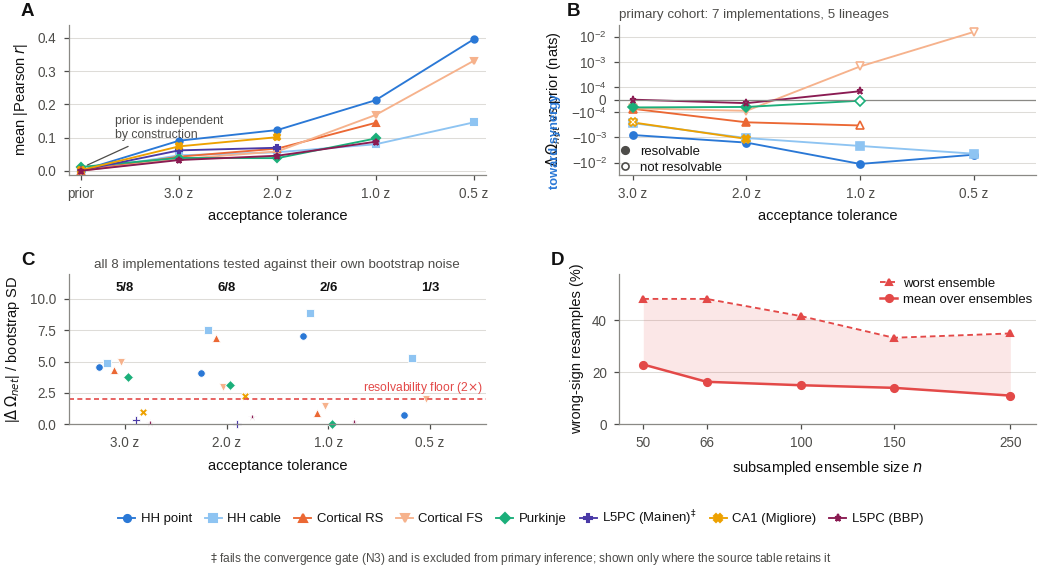

In [4]:
cs = sl_endpoint(cond_shift, metric=("max_z",))
res = pd.DataFrame(reliab["per_model_resolvability"])
ep = sl_endpoint(endpoints)
OFFS = dict(zip(MODEL_ORDER, np.linspace(-0.25, 0.25, len(MODEL_ORDER))))

fig = plt.figure(figsize=(W2, 3.6))
gs = fig.add_gridspec(2, 2, wspace=0.32, hspace=0.66, left=0.075, right=0.985,
                      top=0.93, bottom=0.19)

# ---- A: correlation is manufactured ---------------------------------------
axA = fig.add_subplot(gs[0, 0])
for m in PANEL:
    xs = [0]
    ys = [float(ep[(ep.model_id == m) & (ep.regime == "E1")]["mean_abs_pearson"].iloc[0])]
    for k, t in enumerate(TOL_ORDER, start=1):
        g = ep[(ep.model_id == m) & (ep.regime == TOL_REGIME[t])]
        if len(g):
            xs.append(k); ys.append(float(g["mean_abs_pearson"].iloc[0]))
    axA.plot(xs, ys, color=MODEL_COLOR[m], marker=MODEL_MARKER[m], ms=3.0,
             lw=0.9, clip_on=False)
axA.set_xticks(range(5))
axA.set_xticklabels(["prior"] + [TOL_LABEL[t] for t in TOL_ORDER])
axA.set_xlabel("acceptance tolerance")
axA.set_ylabel("mean |Pearson $r$|")
axA.set_ylim(-0.012, 0.44)
axA.set_xlim(-0.12, 4.12)
ygrid(axA)
axA.annotate("prior is independent\nby construction", xy=(0.03, 0.012),
             xytext=(0.35, 0.10), fontsize=5.9, color=INK2, linespacing=1.2,
             arrowprops=dict(arrowstyle="-", lw=0.6, color=INK2))
panel(axA, "A", dx=-0.115)

# ---- B: shift in net O-information ----------------------------------------
axB = fig.add_subplot(gs[0, 1])
for m in PANEL:
    xs, ys, ok = [], [], []
    for k, t in enumerate(TOL_ORDER):
        g = cs[(cs.model_id == m) & (cs.tolerance == t)]
        if not len(g):
            continue
        xs.append(k); ys.append(float(g["d_net_o_information"].iloc[0]))
        r = res[(res.model_id == m) & (res.tolerance == t)]
        ok.append(bool(r["resolvable"].iloc[0]) if len(r) else False)
    axB.plot(xs, ys, color=MODEL_COLOR[m], lw=0.9, zorder=2, clip_on=False)
    for x, y, o in zip(xs, ys, ok):
        axB.plot(x, y, marker=MODEL_MARKER[m], ms=3.4, mew=0.8,
                 color=MODEL_COLOR[m] if o else "white",
                 markeredgecolor=MODEL_COLOR[m], zorder=3, clip_on=False)
axB.axhline(0, color=INK3, lw=0.6)
axB.set_yscale("symlog", linthresh=1e-4, linscale=0.45)
axB.set_xticks(range(4)); axB.set_xticklabels([TOL_LABEL[t] for t in TOL_ORDER])
axB.set_xlabel("acceptance tolerance")
axB.set_ylabel("$\\Delta\\,\\Omega_{net}$ vs prior (nats)")
axB.set_title("primary cohort: 7 implementations, 5 lineages",
              fontsize=6.4, color=INK2, pad=3, loc="left")
axB.set_ylim(-3e-2, 3e-2)
axB.set_xlim(-0.12, 3.55)
ygrid(axB)
axB.text(-0.155, 0.22, "toward synergy", transform=axB.transAxes, rotation=90,
         fontsize=6.2, color=SYNERGY, ha="center", va="center", fontweight="bold")
axB.legend(handles=[Line2D([], [], marker="o", color=INK2, ls="none", ms=3.4,
                           label="resolvable"),
                    Line2D([], [], marker="o", color="white", markeredgecolor=INK2,
                           ls="none", ms=3.4, mew=0.8, label="not resolvable")],
           ncol=1, loc="lower left", bbox_to_anchor=(-0.015, -0.02))
panel(axB, "B", dx=-0.125)

# ---- C: effect against its own bootstrap noise -----------------------------
axC = fig.add_subplot(gs[1, 0])
for k, t in enumerate(TOL_ORDER):
    for _, r in res[res.tolerance == t].iterrows():
        m = r["model_id"]
        axC.plot(k + OFFS[m], r["sigma"], marker=MODEL_MARKER[m], ms=3.6,
                 color=MODEL_COLOR[m], mew=0.4, markeredgecolor="white",
                 ls="none", clip_on=False)
axC.axhline(2.0, color=REDUNDANCY, lw=0.8, ls=(0, (3, 2)))
axC.text(3.52, 2.28, "resolvability floor (2$\\times$)", fontsize=5.8,
         color=REDUNDANCY, ha="right", va="bottom")
for k, t in enumerate(TOL_ORDER):
    a = int(res[res.tolerance == t]["resolvable"].sum())
    b = int((res.tolerance == t).sum())
    axC.text(k, 10.6, f"{a}/{b}", fontsize=6.3, ha="center", color=INK, fontweight="bold")
axC.set_title("all 8 implementations tested against their own bootstrap noise",
              fontsize=6.4, color=INK2, pad=3)
axC.set_xticks(range(4)); axC.set_xticklabels([TOL_LABEL[t] for t in TOL_ORDER])
axC.set_xlabel("acceptance tolerance")
axC.set_ylabel("|$\\Delta\\,\\Omega_{net}$| / bootstrap SD")
axC.set_ylim(0, 12.0)
axC.set_xlim(-0.55, 3.55)
axC.set_yticks([0, 2.5, 5, 7.5, 10])
ygrid(axC)
panel(axC, "C", dx=-0.115)

# ---- D: sign reliability vs ensemble size ---------------------------------
axD = fig.add_subplot(gs[1, 1])
byn = reliab["by_n"]
ns = sorted(int(k) for k in byn)
mean = [100 * byn[str(n)]["p_sign_flip_mean"] for n in ns]
worst = [100 * byn[str(n)]["p_sign_flip_max"] for n in ns]
axD.fill_between(ns, mean, worst, color=REDUNDANCY, alpha=0.13, lw=0)
axD.plot(ns, worst, color=REDUNDANCY, lw=0.9, ls=(0, (3, 2)), marker="^", ms=3.0,
         label="worst ensemble")
axD.plot(ns, mean, color=REDUNDANCY, lw=1.2, marker="o", ms=3.4,
         label="mean over ensembles")
axD.set_xscale("log")
fixed_log_ticks(axD, ns, "x")
axD.set_xlabel("subsampled ensemble size $n$")
axD.set_ylabel("wrong-sign resamples (%)")
axD.set_ylim(0, 58)
axD.set_xlim(45, 280)
ygrid(axD)
axD.legend(loc="upper right", ncol=1)
panel(axD, "D", dx=-0.165)

model_legend(fig, PANEL, ncol=8, y=-0.01, note=True)
save(fig, 3)
plt.show()

---
## Figure 4 — Result 2: the naive synergy statistic is not a statistic

The quantity this literature reports — the fraction of parameter tuples with
$\Omega<0$ — is compared here with a family-wise surrogate distribution built
from column-shuffled ensembles evaluated over the *same number of tuples*. In
**E8**, an ensemble whose dependence has been deliberately destroyed, the naive
statistic still reports ~45% "synergy-dominated" tuples, at every order and in
every model. Surrogate control returns 0.000.

  wrote Figure_4.pdf / .png  (180 x 86 mm)


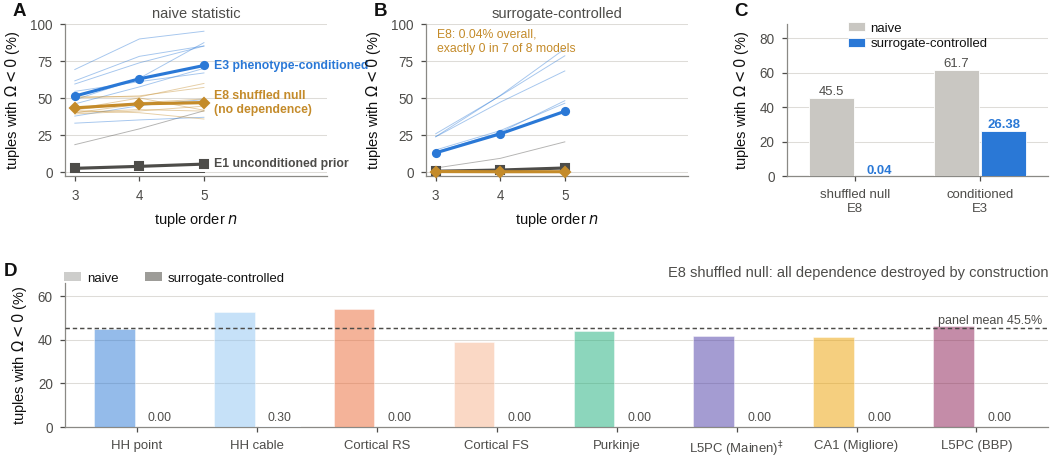

In [5]:
cu = sl_gaussian(curves)                      # the slice RESULTS.md 7 reports
orders = sorted(cu["order"].unique())
SHOW = [("E1", "#4d4c49", "s", "E1 unconditioned prior"),
        ("E3", SYNERGY, "o", "E3 phenotype-conditioned"),
        ("E8", "#c48b2a", "D", "E8 shuffled null (no dependence)")]

fig = plt.figure(figsize=(W2, 3.4))
gs = fig.add_gridspec(2, 3, wspace=0.38, hspace=0.72, left=0.065, right=0.99,
                      top=0.90, bottom=0.11, height_ratios=[1, 0.95])


def per_model_curve(regime, key):
    """model x order matrix, averaging protocol families and metrics."""
    g = cu[cu.regime == regime].groupby(["model_id", "order"])[key].mean().unstack()
    return g.reindex(columns=orders)


for idx, (col, key, ttl) in enumerate([(0, "frac_synergy", "naive statistic"),
                                       (1, "frac_synergy_sig", "surrogate-controlled")]):
    ax = fig.add_subplot(gs[0, col])
    for r, c, mk, lab in SHOW:
        Mt = per_model_curve(r, key)
        for _, row in Mt.iterrows():
            ax.plot(orders, 100 * row.values, color=c, lw=0.45, alpha=0.42, zorder=2)
        ax.plot(orders, 100 * Mt.mean(axis=0).values, color=c, lw=1.5, marker=mk,
                ms=3.4, label=lab, zorder=3, clip_on=False)
    ax.set_xticks(orders)
    ax.set_xlabel("tuple order $n$")
    ax.set_ylabel("tuples with $\\Omega<0$ (%)")
    ax.set_ylim(-3, 100)
    ax.set_xlim(2.85, 6.9)
    ax.set_title(ttl, fontsize=7, color=INK2, pad=3)
    ygrid(ax)
    panel(ax, "AB"[idx], dx=-0.20)
    if col == 0:
        # direct labels rather than a legend box, which would cover the
        # per-model lines in the upper-left quadrant
        for r, c, mk, lab in SHOW:
            yv = 100 * per_model_curve(r, key).mean(axis=0).values[-1]
            ax.text(5.15, yv, lab.replace(" (", "\n("), fontsize=5.9, color=c,
                    va="center", ha="left", linespacing=1.15, fontweight="bold")
    else:
        e8m = cu[cu.regime == "E8"].groupby("model_id")["frac_synergy_sig"].mean()
        ax.text(3.02, 97, f"E8: {100*e8m.mean():.2f}% overall,\nexactly 0 in "
                f"{int((e8m == 0).sum())} of {len(e8m)} models", fontsize=5.9,
                color="#c48b2a", linespacing=1.2, va="top", ha="left")

# ---- C: the headline contraction ------------------------------------------
axC = fig.add_subplot(gs[0, 2])
pairs = [("E8", "shuffled null\nE8"), ("E3", "conditioned\nE3")]
x = np.arange(len(pairs))
naive = [100 * cu[cu.regime == r]["frac_synergy"].mean() for r, _ in pairs]
ctrl = [100 * cu[cu.regime == r]["frac_synergy_sig"].mean() for r, _ in pairs]
axC.bar(x - 0.19, naive, width=0.36, color=FAINT, edgecolor="white", lw=0.4,
        label="naive", zorder=3)
axC.bar(x + 0.19, ctrl, width=0.36, color=SYNERGY, edgecolor="white", lw=0.4,
        label="surrogate-controlled", zorder=3)
for xi, (a, b) in enumerate(zip(naive, ctrl)):
    axC.text(xi - 0.19, a + 1.6, f"{a:.1f}", ha="center", fontsize=6.3, color=INK2)
    axC.text(xi + 0.19, b + 1.6, f"{b:.2f}", ha="center", fontsize=6.3, color=SYNERGY,
             fontweight="bold")
axC.set_xticks(x); axC.set_xticklabels([l for _, l in pairs], fontsize=6.3, linespacing=1.2)
axC.set_ylabel("tuples with $\\Omega<0$ (%)")
axC.set_ylim(0, 88)
axC.set_xlim(-0.55, 1.55)
ygrid(axC)
axC.legend(loc="upper center", bbox_to_anchor=(0.5, 1.04), ncol=1)
panel(axC, "C", dx=-0.20)

# ---- D: per model, the null still reports ~45% synergy ---------------------
axD = fig.add_subplot(gs[1, :])
e8 = cu[cu.regime == "E8"]
w = 0.34
for i, m in enumerate(PANEL):
    g = e8[e8.model_id == m]
    if not len(g):
        continue
    axD.bar(i - w / 2 - 0.02, 100 * g["frac_synergy"].mean(), width=w,
            color=MODEL_COLOR[m], alpha=0.5, edgecolor="white", lw=0.4, zorder=3)
    v = 100 * g["frac_synergy_sig"].mean()
    axD.bar(i + w / 2 + 0.02, v, width=w, color=MODEL_COLOR[m],
            edgecolor="white", lw=0.4, zorder=3)
    axD.text(i + w / 2 + 0.02, 1.6, f"{v:.2f}", ha="center", va="bottom",
             fontsize=5.8, color=INK2)
pm = 100 * e8["frac_synergy"].mean()
axD.axhline(pm, color=INK2, lw=0.7, ls=(0, (3, 2)), zorder=4)
axD.text(7.55, pm + 1.6, f"panel mean {pm:.1f}%", fontsize=6, color=INK2, ha="right")
axD.set_xticks(range(len(PANEL)))
axD.set_xticklabels([mlab(m) for m in PANEL], fontsize=6.3)
axD.set_ylabel("tuples with $\\Omega<0$ (%)")
axD.set_ylim(0, 66)
axD.set_xlim(-0.6, 7.6)
ygrid(axD)
axD.legend(handles=[Patch(facecolor=NEUTRAL, alpha=0.5, label="naive"),
                    Patch(facecolor=NEUTRAL, label="surrogate-controlled")],
           ncol=2, loc="upper left", bbox_to_anchor=(-0.005, 1.10))
axD.set_title("E8 shuffled null: all dependence destroyed by construction",
              fontsize=7, color=INK2, pad=3, loc="right")
panel(axD, "D", dx=-0.062, dy=1.02)

save(fig, 4)
plt.show()

---
## Figure 5 — Results 3–5: the regime, not the neuron, sets the sign

If the synergy–redundancy balance were a property of the neuron, rows of the map
in **A** would be internally consistent and differ from one another. They are
not: columns are. Sampling and geometry carry essentially all of the unique
endpoint variance and model identity carries none of it (**C**); a held-out
source lineage's endpoints are predicted from sampling and geometry while
architecture predicts nothing (**D**); and target-specific information (RSI) — a
different object from dependence among parameters — moves in the *opposite*
direction under the same conditioning (**E**).

  wrote Figure_5.pdf / .png  (180 x 107 mm)


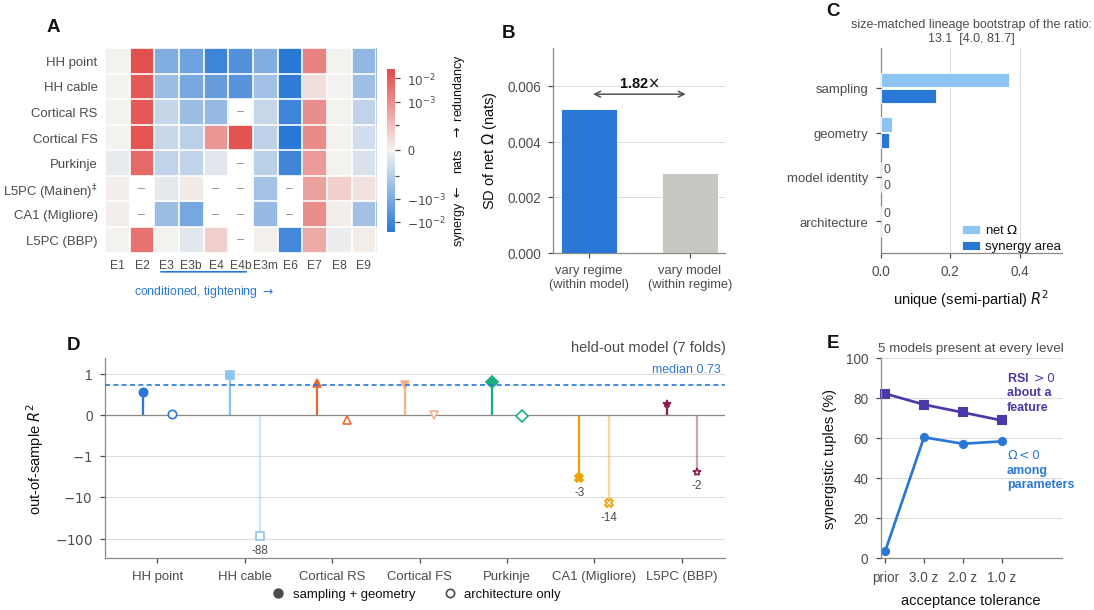

In [6]:
ep = sl_endpoint(endpoints)
REG_SHOW = ["E1", "E2", "E3", "E3b", "E4", "E4b", "E3m", "E6", "E7", "E8", "E9"]

fig = plt.figure(figsize=(W2, 4.2))
gs = fig.add_gridspec(2, 3, width_ratios=[1.62, 0.95, 1.0], height_ratios=[1.0, 0.98],
                      wspace=0.72, hspace=0.52, left=0.085, right=0.985,
                      top=0.92, bottom=0.11)

# ---- A: regime x model map -------------------------------------------------
axA = fig.add_subplot(gs[0, 0])
Mx = np.full((len(PANEL), len(REG_SHOW)), np.nan)
for i, m in enumerate(PANEL):
    for j, r in enumerate(REG_SHOW):
        g = ep[(ep.model_id == m) & (ep.regime == r)]
        if len(g):
            Mx[i, j] = float(g["net_o_information"].iloc[0])
lim = np.nanmax(np.abs(Mx))
norm = mpl.colors.SymLogNorm(linthresh=1e-4, vmin=-lim, vmax=lim, base=10)
im = axA.imshow(Mx, cmap=DIVERGING, norm=norm, aspect="auto")
axA.set_xticks(range(len(REG_SHOW)))
axA.set_xticklabels(REG_SHOW, fontsize=5.8)
axA.set_yticks(range(len(PANEL)))
axA.set_yticklabels([mlab(m) for m in PANEL], fontsize=6.3)
axA.tick_params(length=0)
for i in range(len(PANEL)):
    for j in range(len(REG_SHOW)):
        if np.isnan(Mx[i, j]):
            axA.text(j, i, "–", ha="center", va="center", fontsize=6, color=INK3)
axA.set_xticks(np.arange(-.5, len(REG_SHOW), 1), minor=True)
axA.set_yticks(np.arange(-.5, len(PANEL), 1), minor=True)
axA.grid(which="minor", color="white", lw=0.8)
axA.tick_params(which="minor", length=0)
for s in axA.spines.values():
    s.set_visible(False)
# bracket marking the conditioning ladder
axA.annotate("", xy=(1.6, 8.25), xytext=(5.4, 8.25), annotation_clip=False,
             arrowprops=dict(arrowstyle="-", lw=0.8, color=SYNERGY))
axA.text(3.5, 8.70, "conditioned, tightening $\\rightarrow$", ha="center", va="top",
         fontsize=5.9, color=SYNERGY, clip_on=False)
cb = fig.colorbar(im, ax=axA, fraction=0.040, pad=0.035, shrink=0.80,
                  ticks=[-1e-2, -1e-3, 0, 1e-3, 1e-2])
cb.ax.set_yticklabels(["$-10^{-2}$", "$-10^{-3}$", "0", "$10^{-3}$", "$10^{-2}$"],
                      fontsize=5.8)
cb.set_label("synergy $\\leftarrow$   nats   $\\rightarrow$ redundancy",
             fontsize=6.0, labelpad=2)
cb.outline.set_visible(False)
panel(axA, "A", dx=-0.215, dy=1.06)

# ---- B: within-model vs within-regime spread ------------------------------
axB = fig.add_subplot(gs[0, 1])
wm = ep.groupby("model_id")["net_o_information"].std().mean()
wr = ep.groupby("regime")["net_o_information"].std().mean()
axB.bar([0, 1], [wm, wr], width=0.55, color=[SYNERGY, FAINT],
        edgecolor="white", lw=0.4, zorder=3)
axB.set_xticks([0, 1])
axB.set_xticklabels(["vary regime\n(within model)", "vary model\n(within regime)"],
                    fontsize=6.2, linespacing=1.2)
axB.set_ylabel("SD of net $\\Omega$ (nats)")
axB.set_ylim(0, wm * 1.42)
axB.annotate("", xy=(0, wm * 1.10), xytext=(1, wm * 1.10),
             arrowprops=dict(arrowstyle="<->", lw=0.7, color=INK2))
axB.text(0.5, wm * 1.15, f"{wm/wr:.2f}$\\times$", ha="center", fontsize=7,
         fontweight="bold", color=INK)
ygrid(axB)
panel(axB, "B", dx=-0.30)

# ---- C: unique variance by predictor block --------------------------------
axC = fig.add_subplot(gs[0, 2])
BLOCKS = ["sampling", "geometry", "model_identity", "architecture"]
BLAB = {"sampling": "sampling", "geometry": "geometry",
        "model_identity": "model identity", "architecture": "architecture"}
ENDS = [("synergy_area", SYNERGY, "synergy area"),
        ("net_o_information", "#8ec4f2", "net $\\Omega$")]
y = np.arange(len(BLOCKS))
for k, (e, c, lab) in enumerate(ENDS):
    vals = [float(vpart[(vpart.endpoint == e) & (vpart.block == b)]["r2_unique"].iloc[0])
            for b in BLOCKS]
    axC.barh(y + (0.5 - k) * 0.36, vals, height=0.32, color=c, edgecolor="white",
             lw=0.4, label=lab, zorder=3)
    for yy, v in zip(y + (0.5 - k) * 0.36, vals):
        if v < 1e-4:
            axC.text(0.008, yy, "0", va="center", ha="left", fontsize=5.8, color=INK2)
axC.set_yticks(y); axC.set_yticklabels([BLAB[b] for b in BLOCKS], fontsize=6.3)
axC.invert_yaxis()
axC.set_xlabel("unique (semi-partial) $R^2$")
axC.set_xlim(0, 0.52)
axC.set_ylim(3.7, -0.9)
axC.grid(True, axis="x", color=GRID, lw=0.5); axC.set_axisbelow(True)
h_, l_ = axC.get_legend_handles_labels()
axC.legend(h_[::-1], l_[::-1], loc="lower right", bbox_to_anchor=(1.02, -0.02), ncol=1)
rb = robust["cluster_bootstrap_matched"]["synergy_area"]
axC.set_title("size-matched lineage bootstrap of the ratio:\n%.1f  [%.1f, %.1f]"
              % (rb["ratio_median"], rb["ratio_q025"], rb["ratio_q975"]),
              fontsize=6.0, color=INK2, pad=3, linespacing=1.25)
panel(axC, "C", dx=-0.30, dy=1.14)

# ---- D: leave-one-lineage-out transfer ------------------------------------
axD = fig.add_subplot(gs[1, :2])
# NOTE: lomo.parquet stores fold_level="source_lineage_id" rows that are
# byte-identical to the fold_level="model_id" rows (one held-out model per
# fold, seven folds), so this panel is labelled leave-one-MODEL-out, which is
# what the table implements.
lo = lomo[(lomo.endpoint == "synergy_area") & (lomo.fold_level == "model_id")]
held = [m for m in MODEL_ORDER if m in set(lo.held_out_model)]


def _r2(m, pred):
    return float(lo[(lo.held_out_model == m) & (lo.predictors == pred)]["r2_out_of_sample"].iloc[0])


for i, m in enumerate(held):
    a, b = _r2(m, "sampling+geometry"), _r2(m, "architecture_only")
    for xo, v, fill in ((-0.17, a, True), (0.17, b, False)):
        axD.plot([i + xo, i + xo], [0, v], color=MODEL_COLOR[m], lw=1.1,
                 alpha=1.0 if fill else 0.40, zorder=2, solid_capstyle="butt")
        axD.plot(i + xo, v, marker=MODEL_MARKER[m], ms=4.0, mew=0.8, zorder=3,
                 color=MODEL_COLOR[m] if fill else "white",
                 markeredgecolor=MODEL_COLOR[m])
    for xo, v in ((-0.17, a), (0.17, b)):
        if v < -1.5:
            axD.text(i + xo, v * 1.55, f"{v:.0f}", ha="center", va="top",
                     fontsize=5.6, color=INK2)
med = float(lo[lo.predictors == "sampling+geometry"]["r2_out_of_sample"].median())
axD.axhline(med, color=SYNERGY, lw=0.8, ls=(0, (3, 2)), zorder=4)
axD.text(6.45, med * 1.45, f"median {med:.2f}", fontsize=6, color=SYNERGY, ha="right")
axD.axhline(0, color=INK3, lw=0.6)
axD.set_yscale("symlog", linthresh=1.0, linscale=0.9)
axD.set_yticks([-100, -10, -1, 0, 1])
axD.set_yticklabels(["$-100$", "$-10$", "$-1$", "0", "1"])
axD.yaxis.set_minor_locator(NullLocator())
axD.set_xticks(range(len(held)))
axD.set_xticklabels([mlab(m) for m in held], fontsize=6.3)
axD.set_ylabel("out-of-sample $R^2$")
axD.set_ylim(-300, 2.4)
axD.set_xlim(-0.6, 6.5)
ygrid(axD)
axD.legend(handles=[Line2D([], [], marker="o", color=INK2, ls="none", ms=4,
                           label="sampling + geometry"),
                    Line2D([], [], marker="o", color="white", markeredgecolor=INK2,
                           ls="none", ms=4, mew=0.8, label="architecture only")],
           ncol=2, loc="upper center", bbox_to_anchor=(0.5, -0.13))
axD.set_title("held-out model (7 folds)", fontsize=7, color=INK2, pad=3, loc="right")
panel(axD, "D", dx=-0.062, dy=1.02)

# ---- E: O-information and RSI move in opposite directions ------------------
axE = fig.add_subplot(gs[1, 2])
LAD = ["E1", "E3", "E3b", "E4"]
LADX = ["prior", "3.0 z", "2.0 z", "1.0 z"]
# Both series are restricted to the models present at every level, so the
# comparison is not confounded by a panel whose composition changes.
om_t = ep[ep.regime.isin(LAD)].pivot_table(index="model_id", columns="regime",
                                           values="frac_synergy_o3")[LAD]
rs_t = (sl_rsi(rsi_tab).groupby(["model_id", "regime"])["frac_synergistic"]
        .mean().unstack()[LAD])
BAL = sorted(set(om_t.dropna().index) & set(rs_t.dropna().index))
o3 = list(100 * om_t.loc[BAL].mean().values)
rv = list(100 * rs_t.loc[BAL].mean().values)
axE.plot(range(4), o3, color=SYNERGY, marker="o", ms=3.4, lw=1.3, clip_on=False)
axE.plot(range(4), rv, color="#4a3aa7", marker="s", ms=3.4, lw=1.3, clip_on=False)
axE.text(3.14, o3[-1] - 14, "$\\Omega<0$\namong\nparameters", color=SYNERGY,
         fontsize=6.0, va="center", ha="left", linespacing=1.25, fontweight="bold")
axE.text(3.14, rv[-1] + 14, "RSI $>0$\nabout a\nfeature", color="#4a3aa7",
         fontsize=6.0, va="center", ha="left", linespacing=1.25, fontweight="bold")
axE.set_xticks(range(4)); axE.set_xticklabels(LADX)
axE.set_xlabel("acceptance tolerance")
axE.set_ylabel("synergistic tuples (%)")
axE.set_ylim(0, 100)
axE.set_xlim(-0.12, 4.55)
ygrid(axE)
axE.set_title(f"{len(BAL)} models present at every level", fontsize=6.4,
              color=INK2, pad=3)
panel(axE, "E", dx=-0.30)

save(fig, 5)
plt.show()

---
## Figure 6 — Result 6: do statistically synergistic tuples interact functionally?

The decisive test, and the one that does not resolve. The most synergistic
order-3 tuples in each model's conditioned ensemble are perturbed singly and
jointly at eight background points drawn from the accepted manifold, and the
non-additivity

$$\eta=\Big[f\big(x_0+\textstyle\sum_i\delta_i\big)-f(x_0)\Big]-\sum_i\Big[f(x_0+\delta_i)-f(x_0)\Big]$$

is measured in ensemble-SD units against two control families. Top tuples are
enriched — but the intervals span an order of magnitude (**C**), most individual
tuples are not distinguishable from no interaction (**E**), and the whole effect
is carried by spike-timing readouts and vanishes for waveform readouts measured
on the *same* simulations (**D**). Panel **F** is the parallel Sobol result: at
these base sample sizes most interaction estimates cannot support a quantitative
statement in either direction.

  wrote Figure_6.pdf / .png  (180 x 109 mm)


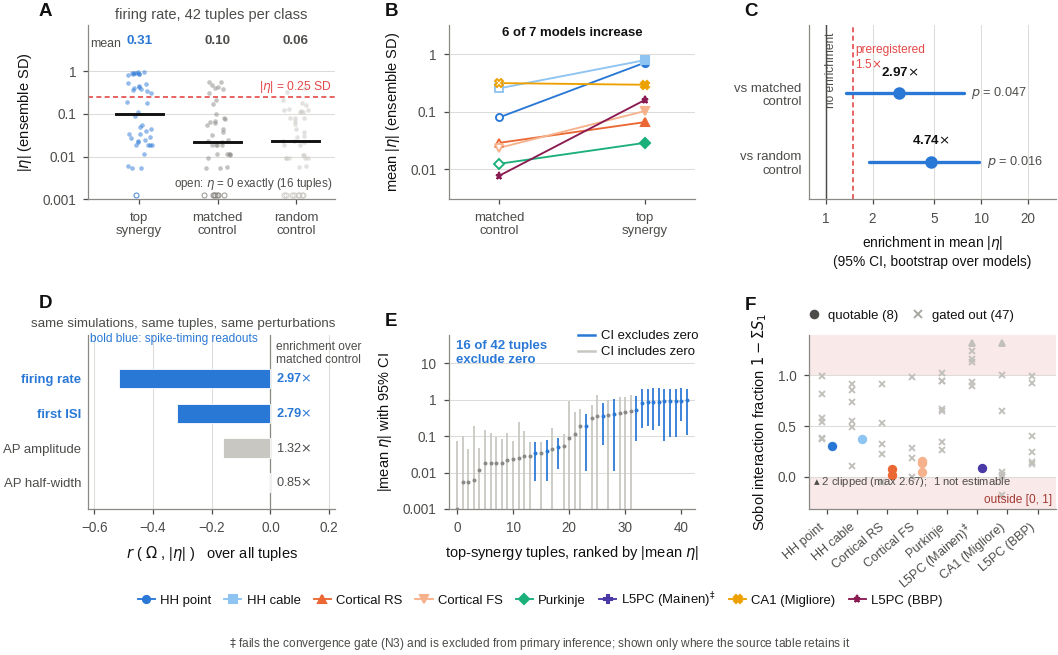

In [7]:
prim = pert[pert["primary_feature"]].copy()
prim["abs_eta"] = prim["mean_nonadditivity_sd"].abs()
PRIMARY_FEATURE = str(prim["feature"].iloc[0])
KINDS = ["top_synergy", "control_middle", "control_random"]
PERT_MODELS = [m for m in MODEL_ORDER if m in set(prim.model_id)]

fig = plt.figure(figsize=(W2, 4.3))
gs = fig.add_gridspec(2, 3, wspace=0.46, hspace=0.78, left=0.075, right=0.985,
                      top=0.90, bottom=0.15)

# ---- A: |eta| by tuple class ----------------------------------------------
axA = fig.add_subplot(gs[0, 0])
rng = np.random.RandomState(7)
n_zero = 0
for i, k in enumerate(KINDS):
    v = prim[prim.kind == k]["abs_eta"].values
    jit = rng.uniform(-0.17, 0.17, len(v))
    pos, zer = v > 0, v == 0
    n_zero += int(zer.sum())
    axA.plot(i + jit[pos], v[pos], ls="none", marker="o", ms=2.2, mew=0,
             alpha=0.5, color=KIND_COLOR[k])
    axA.plot(i + jit[zer], np.full(int(zer.sum()), 1.25e-3), ls="none", marker="o",
             ms=2.4, mew=0.5, mfc="none", markeredgecolor=KIND_COLOR[k], alpha=0.85)
    axA.plot([i - 0.30, i + 0.30], [np.median(v)] * 2, color=INK, lw=1.4, zorder=4)
    axA.text(i, 4.4, f"{np.mean(v):.2f}", ha="center", fontsize=6.4,
             color=SYNERGY if k == "top_synergy" else INK2, fontweight="bold")
axA.text(2.46, 1.45e-3, f"open: $\\eta$ = 0 exactly ({n_zero} tuples)", fontsize=5.6,
         color=INK2, ha="right", va="bottom")
axA.text(-0.62, 4.4, "mean", fontsize=5.9, ha="left", va="center", color=INK2)
axA.axhline(0.25, color=REDUNDANCY, lw=0.8, ls=(0, (3, 2)))
axA.text(2.46, 0.285, "|$\\eta$| = 0.25 SD", fontsize=5.8, color=REDUNDANCY,
         ha="right", va="bottom")
axA.set_yscale("log")
fixed_log_ticks(axA, [0.001, 0.01, 0.1, 1], "y")
axA.set_xticks(range(3))
axA.set_xticklabels([KIND_LABEL[k].replace(" ", "\n") for k in KINDS], fontsize=6.3,
                    linespacing=1.15)
axA.set_ylabel("|$\\eta$| (ensemble SD)")
axA.set_ylim(1e-3, 12)
axA.set_xlim(-0.65, 2.5)
ygrid(axA)
axA.set_title(f"{FEATURE_LABEL[PRIMARY_FEATURE]}, {len(prim)//3} tuples per class",
              fontsize=7, color=INK2, pad=3)
panel(axA, "A", dx=-0.20)

# ---- B: paired per model ---------------------------------------------------
axB = fig.add_subplot(gs[0, 1])
per = prim.groupby(["model_id", "kind"])["abs_eta"].mean().unstack()
for m in PERT_MODELS:
    a, b = per.loc[m, "control_middle"], per.loc[m, "top_synergy"]
    axB.plot([0, 1], [a, b], color=MODEL_COLOR[m], lw=0.9, zorder=2)
    axB.plot(0, a, marker=MODEL_MARKER[m], ms=3.4, color="white",
             markeredgecolor=MODEL_COLOR[m], mew=0.9, zorder=3)
    axB.plot(1, b, marker=MODEL_MARKER[m], ms=3.4, color=MODEL_COLOR[m], zorder=3)
axB.set_xticks([0, 1])
axB.set_xticklabels(["matched\ncontrol", "top\nsynergy"], fontsize=6.3, linespacing=1.15)
axB.set_yscale("log")
fixed_log_ticks(axB, [0.01, 0.1, 1], "y")
axB.set_ylabel("mean |$\\eta$| (ensemble SD)")
axB.set_xlim(-0.35, 1.35)
axB.set_ylim(3e-3, 3.2)
n_up = int((per["top_synergy"] > per["control_middle"]).sum())
axB.text(0.5, 2.1, f"{n_up} of {len(PERT_MODELS)} models increase", ha="center",
         fontsize=6.3, color=INK, fontweight="bold")
ygrid(axB)
panel(axB, "B", dx=-0.26)

# ---- C: enrichment ratios with model-bootstrap CI --------------------------
axC = fig.add_subplot(gs[0, 2])
rows = [("top_vs_control_random", "vs random\ncontrol"),
        ("top_vs_control_middle", "vs matched\ncontrol")]
for i, (key, lab) in enumerate(rows):
    d = pert_sum[key]
    lo, hi, pt = d["ratio_ci95"][0], d["ratio_ci95"][1], d["ratio_point"]
    axC.plot([lo, hi], [i, i], color=SYNERGY, lw=1.6, solid_capstyle="round", zorder=3)
    axC.plot(pt, i, marker="o", ms=5, color=SYNERGY, zorder=4)
    axC.text(pt, i + 0.26, f"{pt:.2f}$\\times$", ha="center", fontsize=6.4,
             color=INK, fontweight="bold")
    axC.text(hi * 1.12, i, f"$p$ = {d['wilcoxon_p']:.3f}", fontsize=6.1,
             va="center", color=INK2)
axC.axvline(1.0, color=INK2, lw=0.7)
axC.axvline(1.5, color=REDUNDANCY, lw=0.8, ls=(0, (3, 2)))
axC.text(1.55, 1.72, "preregistered\n1.5$\\times$", fontsize=5.7, color=REDUNDANCY,
         va="top", linespacing=1.15)
axC.text(0.99, 1.90, "no enrichment", fontsize=5.7, color=INK2, ha="left",
         va="top", rotation=90)
axC.set_yticks(range(len(rows)))
axC.set_yticklabels([l for _, l in rows], fontsize=6.3, linespacing=1.15)
axC.set_ylim(-0.55, 2.0)
axC.set_xscale("log")
fixed_log_ticks(axC, [1, 2, 5, 10, 20], "x")
axC.set_xlim(0.78, 30)
axC.set_xlabel("enrichment in mean |$\\eta$|\n(95% CI, bootstrap over models)",
               fontsize=6.6, linespacing=1.25)
axC.tick_params(axis="y", length=0)
axC.grid(True, axis="x", color=GRID, lw=0.5); axC.set_axisbelow(True)
panel(axC, "C", dx=-0.26)

# ---- D: the readout decides ------------------------------------------------
axD = fig.add_subplot(gs[1, 0])
FEATS = ["mean_firing_rate_Hz", "first_isi_ms", "ap_amplitude_mV", "ap_halfwidth_ms"]
TIMING = {"mean_firing_rate_Hz", "first_isi_ms"}
rs, en = [], []
for f in FEATS:
    g = pert[pert.feature == f]
    rs.append(float(np.corrcoef(g["o_information"], g["mean_nonadditivity_sd"].abs())[0, 1]))
    bf = pert_sum["by_feature"][f]["mean_abs_eta_sd"]
    en.append(bf["top_synergy"] / bf["control_middle"])
y = np.arange(len(FEATS))
axD.barh(y, rs, height=0.55, color=[SYNERGY if f in TIMING else FAINT for f in FEATS],
         edgecolor="white", lw=0.4, zorder=3)
for yy, (f, r, e) in enumerate(zip(FEATS, rs, en)):
    axD.text(0.02, yy, f"{e:.2f}$\\times$", fontsize=6.1, va="center", ha="left",
             color=SYNERGY if f in TIMING else INK2,
             fontweight="bold" if f in TIMING else "normal")
axD.text(0.02, -0.72, "enrichment over\nmatched control", fontsize=5.7, color=INK2,
         va="center", ha="left", linespacing=1.2)
axD.axvline(0, color=INK3, lw=0.6)
axD.set_yticks(y); axD.set_yticklabels([FEATURE_LABEL[f] for f in FEATS], fontsize=6.3)
axD.set_ylim(3.75, -1.25)
axD.set_xlim(-0.62, 0.22)
axD.set_xticks([-0.6, -0.4, -0.2, 0.0, 0.2])
axD.set_xlabel("$r$ ( $\\Omega$ , |$\\eta$| )   over all tuples")
axD.grid(True, axis="x", color=GRID, lw=0.5); axD.set_axisbelow(True)
axD.tick_params(axis="y", length=0)
for _t, _f in zip(axD.get_yticklabels(), FEATS):
    _t.set_color(SYNERGY if _f in TIMING else INK2)
    _t.set_fontweight("bold" if _f in TIMING else "normal")
axD.text(-0.615, -1.12, "bold blue: spike-timing readouts", fontsize=5.7,
         color=SYNERGY, ha="left", va="center")
axD.set_title("same simulations, same tuples, same perturbations",
              fontsize=6.4, color=INK2, pad=4, loc="right")
panel(axD, "D", dx=-0.20, dy=1.13)

# ---- E: per-tuple precision ------------------------------------------------
axE = fig.add_subplot(gs[1, 1])
pi = pert_inf[(pert_inf.kind == "top_synergy")
              & (pert_inf.feature == PRIMARY_FEATURE)].copy()
pi["a"] = pi["mean_eta_sd"].abs()
pi = pi.sort_values("a").reset_index(drop=True)
FLOOR = 1e-3
for i, r in pi.iterrows():
    ok = bool(r["ci_excludes_zero"])
    lo_, hi_ = abs(r["ci95_lo"]), abs(r["ci95_hi"])
    lo_, hi_ = (min(lo_, hi_), max(lo_, hi_)) if ok else (FLOOR, max(lo_, hi_))
    axE.plot([i, i], [max(lo_, FLOOR), max(hi_, FLOOR)],
             color=SYNERGY if ok else FAINT, lw=0.85, solid_capstyle="butt", zorder=2)
    axE.plot(i, max(r["a"], FLOOR), marker="o", ms=1.9, mew=0,
             color=SYNERGY if ok else INK3, zorder=3)
axE.set_yscale("log")
fixed_log_ticks(axE, [0.001, 0.01, 0.1, 1, 10], "y")
axE.set_ylim(FLOOR, 60)
axE.set_xlim(-1.5, len(pi) + 0.5)
axE.set_xlabel("top-synergy tuples, ranked by |mean $\\eta$|")
axE.set_ylabel("|mean $\\eta$| with 95% CI")
n_ok = int(pi["ci_excludes_zero"].sum())
axE.text(0.03, 0.97, f"{n_ok} of {len(pi)} tuples\nexclude zero", transform=axE.transAxes,
         fontsize=6.3, va="top", color=SYNERGY, linespacing=1.2, fontweight="bold")
axE.legend(handles=[Line2D([], [], color=SYNERGY, lw=1.2, label="CI excludes zero"),
                    Line2D([], [], color=FAINT, lw=1.2, label="CI includes zero")],
           loc="upper right", bbox_to_anchor=(1.03, 1.05), ncol=1)
ygrid(axE)
panel(axE, "E", dx=-0.26)

# ---- F: Sobol interaction fractions, precision-gated -----------------------
axF = fig.add_subplot(gs[1, 2])
sb = sobol_sum.dropna(subset=["interaction_fraction"]).copy()
n_nan = int(sobol_sum["interaction_fraction"].isna().sum())
models_f = [m for m in MODEL_ORDER if m in set(sb.model_id)]
HI, n_clip = 1.32, 0
for i, m in enumerate(models_f):
    for _, r in sb[sb.model_id == m].iterrows():
        q = bool(r["quotable"])
        v = float(r["interaction_fraction"])
        clipped = v > HI
        n_clip += int(clipped)
        axF.plot(i + (0.17 if q else -0.17), min(v, HI),
                 marker="o" if q else ("^" if clipped else "x"),
                 ms=3.6 if q else 3.2, mew=0.9,
                 color=MODEL_COLOR[m] if q else "#c2c0bb", ls="none",
                 zorder=3 if q else 2)
axF.axhspan(-0.32, 0.0, color=BAND, alpha=0.4, lw=0, zorder=0)
axF.axhspan(1.0, 1.40, color=BAND, alpha=0.4, lw=0, zorder=0)
axF.set_xticks(range(len(models_f)))
axF.set_xticklabels([mlab(m) for m in models_f], fontsize=6.0, rotation=40, ha="right")
axF.set_ylabel("Sobol interaction fraction $1-\\Sigma S_1$")
axF.set_ylim(-0.32, 1.40)
axF.set_xlim(-0.6, len(models_f) - 0.4)
axF.set_yticks([0, 0.5, 1.0])
ygrid(axF)
nq = int(sobol_sum["quotable"].sum())
axF.legend(handles=[Line2D([], [], marker="o", ls="none", color=INK2, ms=3.6,
                           label=f"quotable ({nq})"),
                    Line2D([], [], marker="x", ls="none", color="#a8a6a1", ms=3.4,
                           mew=0.9, label=f"gated out ({len(sb) - nq})")],
           ncol=2, loc="upper left", bbox_to_anchor=(-0.03, 1.17), columnspacing=0.8)
axF.text(0.985, 0.015, "outside [0, 1]", transform=axF.transAxes, fontsize=5.7,
         color="#a33a34", ha="right", va="bottom")
axF.text(0.015, 0.115, f"$\\blacktriangle$ {n_clip} clipped (max "
         f"{sb.interaction_fraction.max():.2f});  {n_nan} not estimable",
         transform=axF.transAxes, fontsize=5.4, color=INK2, ha="left", va="bottom")
panel(axF, "F", dx=-0.26, dy=1.12)

FIG6_MODELS = [m for m in MODEL_ORDER if m in set(PERT_MODELS) | set(models_f)]
model_legend(fig, FIG6_MODELS, ncol=8, y=-0.012, note=True)
save(fig, 6)
plt.show()

---
## Numbers quoted in the figures and in `docs/figure_legends.md`

Regenerated from the same tables, so a legend and its figure cannot drift apart.
Written to `results/figures/figure_values.csv`.

In [8]:
ep = sl_endpoint(endpoints)
cu = sl_gaussian(curves)
res = pd.DataFrame(reliab["per_model_resolvability"])
prim = pert[pert["primary_feature"]].copy()
bvN = pd.DataFrame(bench["estimator_validation"])
bvN = bvN[bvN.n == bvN.n.max()]
rep = {e["label"]: e for e in bench["comparators"][0]["ensembles"]}
lv = {e["label"]: e for e in bench["comparators"][1]["ensembles"]}
csx = sl_endpoint(cond_shift, metric=("max_z",))


def _o(system, est):
    return float(bvN.query("system==@system and estimator==@est")["o_information"].iloc[0])


def dcrit(name):
    return float(next(c for c in decision["criteria"] if c["criterion"] == name)["value"])


rows = [
 ("1", "models / source lineages / compartment range",
  f"{len(PANEL)} / {len({manifests[m]['manifest']['source_lineage_id'] for m in PANEL})} / "
  f"{min(manifests[m]['n_compartments'] for m in PANEL)}–{max(manifests[m]['n_compartments'] for m in PANEL):,}"),
 ("1", "accepted samples, 3.0 z -> 0.5 z (min over models)",
  "%d -> %d" % (ep[ep.regime == "E3"]["n_samples"].min(), ep[ep.regime == "E4b"]["n_samples"].min())),
 ("2", "Omega for product of three: Gaussian / copula / k-NN",
  "%.3f / %.3f / %.3f" % (_o("multiplicative", "gaussian"), _o("multiplicative", "copula"),
                          _o("multiplicative", "knn"))),
 ("2", "Omega for product of two: Gaussian / copula / k-NN",
  "%.3f / %.3f / %.3f" % (_o("xor_like", "gaussian"), _o("xor_like", "copula"),
                          _o("xor_like", "knn"))),
 ("2", "RSI validation: sum / duplicated / single", " / ".join(
  "%+.2f" % float(r["rsi"]) for _, r in pd.DataFrame(bench["rsi_sign_validation"]).iterrows())),
 ("2", "repressilator mean |r|, prior -> 0.5 z", "%.3f -> %.3f" % (
  rep["E1_unconditioned_prior"]["mean_abs_pearson"], rep["conditioned_very_strict"]["mean_abs_pearson"])),
 ("2", "repressilator Omega, prior -> 0.5 z", "%.4f -> %.4f" % (
  rep["E1_unconditioned_prior"]["o_information_full"], rep["conditioned_very_strict"]["o_information_full"])),
 ("2", "Lotka-Volterra max |Omega| over tolerances", "%.4f" % max(
  abs(v["o_information_full"]) for v in lv.values())),
 ("3", "mean |r| panel mean, prior / 3.0 z / 0.5 z", "%.4f / %.3f / %.3f" % (
  ep[ep.regime == "E1"]["mean_abs_pearson"].mean(), ep[ep.regime == "E3"]["mean_abs_pearson"].mean(),
  ep[ep.regime == "E4b"]["mean_abs_pearson"].mean())),
 ("3", "models moving toward synergy at 3.0 z", "%d/%d" % (
  int((csx.query("tolerance=='permissive'")["d_net_o_information"] < 0).sum()),
  int((csx.tolerance == "permissive").sum()))),
 ("3", "resolvable models by tolerance",
  " -> ".join(str(int(res[res.tolerance == t]["resolvable"].sum())) for t in TOL_ORDER)),
 ("3", "sign-flip rate at n = 50 / 250 (mean over ensembles)", "%.0f%% / %.0f%%" % (
  100 * reliab["by_n"]["50"]["p_sign_flip_mean"], 100 * reliab["by_n"]["250"]["p_sign_flip_mean"])),
 ("4", "E8 fraction Omega<0: naive / surrogate-controlled", "%.4f / %.4f" % (
  cu[cu.regime == "E8"]["frac_synergy"].mean(), cu[cu.regime == "E8"]["frac_synergy_sig"].mean())),
 ("4", "E3 fraction Omega<0: naive / surrogate-controlled", "%.4f / %.4f" % (
  cu[cu.regime == "E3"]["frac_synergy"].mean(), cu[cu.regime == "E3"]["frac_synergy_sig"].mean())),
 ("5", "SD within model / within regime", "%.4f / %.4f  (%.2fx)" % (
  ep.groupby("model_id")["net_o_information"].std().mean(),
  ep.groupby("regime")["net_o_information"].std().mean(),
  ep.groupby("model_id")["net_o_information"].std().mean() /
  ep.groupby("regime")["net_o_information"].std().mean())),
 ("5", "unique R2 sampling / geometry / identity / architecture (synergy area)", " / ".join(
  "%.3f" % float(vpart.query("endpoint=='synergy_area' and block==@b")["r2_unique"].iloc[0])
  for b in ("sampling", "geometry", "model_identity", "architecture"))),
 ("5", "size-matched lineage-bootstrap ratio", "%.1f [%.1f, %.1f], %.0f%% of resamples > 2" % (
  robust["cluster_bootstrap_matched"]["synergy_area"]["ratio_median"],
  robust["cluster_bootstrap_matched"]["synergy_area"]["ratio_q025"],
  robust["cluster_bootstrap_matched"]["synergy_area"]["ratio_q975"],
  100 * robust["cluster_bootstrap_matched"]["synergy_area"]["ratio_gt_2_fraction"])),
 ("5", "leave-one-lineage-out R2 (sampling+geometry): median / worst", "%.3f / %.3f" % (
  lomo.query("endpoint=='synergy_area' and fold_level=='source_lineage_id' and "
             "predictors=='sampling+geometry'")["r2_out_of_sample"].median(),
  lomo.query("endpoint=='synergy_area' and fold_level=='source_lineage_id' and "
             "predictors=='sampling+geometry'")["r2_out_of_sample"].min())),
 ("5", "adjusted ICC / VPC of model identity (descriptive)", "%.3f / %.3f" % (
  mixed["flat"]["icc_adjusted"], mixed["flat"]["vpc_model_identity"])),
 ("5", "fraction Omega<0 (order 3), prior -> 1.0 z", "%.3f -> %.3f" % (
  ep[ep.regime == "E1"]["frac_synergy_o3"].mean(), ep[ep.regime == "E4"]["frac_synergy_o3"].mean())),
 ("5", "fraction RSI>0, prior -> 1.0 z", "%.3f -> %.3f" % (
  rsi_tab.query("estimator=='gaussian' and regime=='E1'")["frac_synergistic"].mean(),
  rsi_tab.query("estimator=='gaussian' and regime=='E4'")["frac_synergistic"].mean())),
 ("6", "mean |eta|: top / matched / random (%s)" % PRIMARY_FEATURE, "%.3f / %.3f / %.3f" % tuple(
  prim[prim.kind == k]["mean_nonadditivity_sd"].abs().mean()
  for k in ("top_synergy", "control_middle", "control_random"))),
 ("6", "meeting the functional-support bar: top / matched / random", "%.1f%% / %.1f%% / %.1f%%" % tuple(
  100 * prim[prim.kind == k]["functionally_supported"].mean()
  for k in ("top_synergy", "control_middle", "control_random"))),
 ("6", "enrichment vs random control", "%.2fx [%.2f, %.2f], p = %.3f, %d/%d models" % (
  pert_sum["top_vs_control_random"]["ratio_point"], *pert_sum["top_vs_control_random"]["ratio_ci95"],
  pert_sum["top_vs_control_random"]["wilcoxon_p"],
  pert_sum["top_vs_control_random"]["n_models_top_greater"],
  pert_sum["top_vs_control_random"]["n_models"])),
 ("6", "enrichment vs matched control", "%.2fx [%.2f, %.2f], p = %.3f, %d/%d models" % (
  pert_sum["top_vs_control_middle"]["ratio_point"], *pert_sum["top_vs_control_middle"]["ratio_ci95"],
  pert_sum["top_vs_control_middle"]["wilcoxon_p"],
  pert_sum["top_vs_control_middle"]["n_models_top_greater"],
  pert_sum["top_vs_control_middle"]["n_models"])),
 ("6", "top tuples whose bootstrap CI excludes zero", "%d/%d" % (
  pert_prec["inferential_precision"]["n_top_tuples_ci_excludes_zero"],
  pert_prec["inferential_precision"]["n_top_tuples_total"])),
 ("6", "Pearson r(Omega,|eta|): rate / ISI / AP amplitude / AP half-width", " / ".join(
  "%+.3f" % np.corrcoef(pert[pert.feature == f]["o_information"],
                        pert[pert.feature == f]["mean_nonadditivity_sd"].abs())[0, 1]
  for f in ("mean_firing_rate_Hz", "first_isi_ms", "ap_amplitude_mV", "ap_halfwidth_ms"))),
 ("6", "Spearman rho(Omega,|eta|): rate / ISI / AP amplitude / AP half-width", " / ".join(
  "%+.3f" % pert[pert.feature == f][["o_information", "mean_nonadditivity_sd"]]
  .assign(a=lambda d: d["mean_nonadditivity_sd"].abs())[["o_information", "a"]]
  .corr(method="spearman").iloc[0, 1]
  for f in ("mean_firing_rate_Hz", "first_isi_ms", "ap_amplitude_mV", "ap_halfwidth_ms"))),
 ("6", "top-synergy mean |eta| per model, largest / smallest", "%s %.3f / %s %.3f" % (
  *[x for m, v in [max(pert_sum["per_model_mean_abs_eta"]["top_synergy"].items(), key=lambda kv: kv[1])] for x in (m, v)],
  *[x for m, v in [min(pert_sum["per_model_mean_abs_eta"]["top_synergy"].items(), key=lambda kv: kv[1])] for x in (m, v)])),
 ("6", "enrichment by readout: rate / ISI / amplitude / half-width", " / ".join(
  "%.2fx" % (pert_sum["by_feature"][f]["mean_abs_eta_sd"]["top_synergy"] /
             pert_sum["by_feature"][f]["mean_abs_eta_sd"]["control_middle"])
  for f in ("mean_firing_rate_Hz", "first_isi_ms", "ap_amplitude_mV", "ap_halfwidth_ms"))),
 ("6", "Sobol analyses quotable / total", "%d / %d" % (
  int(sobol_sum["quotable"].sum()), len(sobol_sum))),
 ("6", "mean Sobol interaction fraction, quotable / ungated", "%.3f / %.3f" % (
  sobol_sum[sobol_sum.quotable]["interaction_fraction"].mean(),
  sobol_sum["interaction_fraction"].mean())),
 ("1", "screening / Saltelli simulations, failed", "%s / %s / 0" % (
  f"{int(js('key_numbers.json')['campaign']['total_simulated_samples']):,}",
  f"{int(js('key_numbers.json')['campaign']['sobol_samples']):,}")),
 ("1", "source publication span", "1952-2011"),
 ("5", "endpoint rows entering the variance partition", "%d" % int(vpart["n"].iloc[0])),
 ("6", "top tuples above |eta| = 0.25 SD (line drawn in 6A)", "%.1f%%" % (
  100 * (prim[prim.kind == "top_synergy"]["mean_nonadditivity_sd"].abs() >= 0.25).mean())),
 ("6", "prereg functional-support criterion (needs >= 0.50)", "%.3f - NOT MET" % (
  dcrit("statistical synergy modules validated by direct perturbation"))),
 ("6", "numerical-repeatability gate", "%d of %d models pass" % (
  sum(1 for v in pert_prec["numerical_repeatability"]["per_model"].values()
      if v["numerically_repeatable"]),
  len(pert_prec["numerical_repeatability"]["per_model"]))),
 ("6", "half-dt sign flips by base effect size", "; ".join(
  "%s: %d/%d" % (k, v["n_sign_flipped"], v["n_tuples"])
  for k, v in pert_prec["numerical_repeatability"]["sign_stability_by_effect_size"].items())),
 ("-", "preregistered decision (primary arm)", "H-G %d/%d, H-B %d/%d -> %s" % (
  decision["n_hg_passed"], decision["n_hg_total"], decision["n_hb_passed"],
  decision["n_hb_total"], decision["conclusion"])),
]
summary = pd.DataFrame(rows, columns=["figure", "quantity", "value"])
pd.set_option("display.max_colwidth", 100)
summary.to_csv(FIGDIR / "figure_values.csv", index=False)
print("wrote", FIGDIR / "figure_values.csv", "\n")
display(summary.style.hide(axis="index"))

wrote /home/claude/work/compass/results/figures/figure_values.csv 



figure,quantity,value
1,models / source lineages / compartment range,"8 / 6 / 1–2,304"
1,"accepted samples, 3.0 z -> 0.5 z (min over models)",140 -> 66
2,Omega for product of three: Gaussian / copula / k-NN,0.000 / 0.000 / -1.566
2,Omega for product of two: Gaussian / copula / k-NN,0.000 / 0.000 / -0.839
2,RSI validation: sum / duplicated / single,+1.97 / -1.82 / +0.00
2,"repressilator mean |r|, prior -> 0.5 z",0.009 -> 0.204
2,"repressilator Omega, prior -> 0.5 z",0.0000 -> -0.1826
2,Lotka-Volterra max |Omega| over tolerances,0.0003
3,"mean |r| panel mean, prior / 3.0 z / 0.5 z",0.0017 / 0.052 / 0.291
3,models moving toward synergy at 3.0 z,7/7
